Data comparison

Train data

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import scipy
from train_analysis import (
    load_train_data,
    filter_cancellation_days,
    analyse_delays,
    analyse_delays_per_hour,
    analyse_punctuality,
    analyse_delay_absorption,
    analyse_correlations
)
import importlib




import matplotlib.dates as mdates
from matplotlib.colors import BoundaryNorm




Weather

In [10]:

# 1. Load the dataset
# Make sure your file is saved in the same directory and named accordingly.
filename = 'data\weather_selected.csv'

# Find the header row starting with '# STN'
with open(filename, 'r', encoding='utf-8') as f:
    lines = f.readlines()

header_idx = next(i for i, line in enumerate(lines) if line.strip().startswith('# STN'))

# Read the data into a pandas DataFrame
df = pd.read_csv(
    filename,
    skiprows=header_idx,
    skipinitialspace=True
)

# Clean column names by removing '#' and extra whitespace
df.columns = df.columns.str.replace('#', '').str.strip()

# 2. Process Dates and Hours
# KNMI hourly data uses hours 1 to 24. We convert hour 24 properly by adjusting HH - 1.
df['HH_adjusted'] = df['HH'] - 1
df['datetime'] = pd.to_datetime(df['YYYYMMDD'].astype(str), format='%Y%m%d') + pd.to_timedelta(df['HH_adjusted'], unit='h')

# Convert KNMI scaled values to standard units:
# T: Temperature in 0.1 °C -> divide by 10
# TD: Dew point temperature in 0.1 °C -> divide by 10
df['T_C'] = df['T'] / 10.0
df['TD_C'] = df['TD'] / 10.0

# RH: Hourly precipitation amount in 0.1 mm (-1 means <0.05 mm trace amount)
# We convert -1 to 0.0 for numerical plotting, and divide valid values by 10.
df['RH_mm'] = df['RH'].apply(lambda x: 0.0 if x == -1 else x / 10.0)

# 3. Filter data for the specified period
# Note: If testing with the sample snippet from Jan 2021, change dates to '2021-01-01' and '2021-01-14'.
start_date = '2026-01-01'
end_date = '2026-01-14'

mask = (df['datetime'] >= start_date) & (df['datetime'] <= end_date + ' 23:59:59')
df_filtered = df.loc[mask].copy()

# Select columns related to weather variables
columns_of_interest = ['datetime', 'T_C', 'TD_C', 'RH_mm', 'S', 'R', 'WW', 'VV', 'U']
df_weather = df_filtered[columns_of_interest].dropna(subset=['datetime'])

print(f"Filtered dataset contains {len(df_weather)} records for the selected period.")

# 4. Visualizations - Three Completely Separate Figures

# --- Figure 1: Temperature and Snow Occurrences ---
fig1, ax1 = plt.subplots(figsize=(12, 5))
ax1.plot(df_weather['datetime'], df_weather['T_C'], label='Temperature (°C)', color='tab:blue', linewidth=3.0)

snow_df = df_weather[df_weather['S'] == 1]
ax1.scatter(snow_df['datetime'], snow_df['T_C'], color='tab:red', s=60, zorder=5, label='Snow (S=1)')

ax1.set_ylabel('Temperature (°C)')
ax1.set_title(f'Temperature and Snow Occurrences')
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend(loc='upper right')

# --- Figure 2: Temperature vs. Dew Point Comparison ---
fig2, ax2 = plt.subplots(figsize=(12, 5))
ax2.plot(df_weather['datetime'], df_weather['T_C'], label='Temperature (°C)', color='tab:blue', linewidth=3.0)
ax2.plot(df_weather['datetime'], df_weather['TD_C'], label='Dew Point (°C)', color='tab:orange', linewidth=3.0, linestyle='--')

ax2.set_ylabel('Temperature / Dew Point (°C)')
ax2.set_title('Temperature and Dew Point Comparison')
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend(loc='upper right')

# --- Figure 3: Temperature and Precipitation (RH) ---
fig3, ax3_temp = plt.subplots(figsize=(12, 5))
ax3_precip = ax3_temp.twinx()  # Secondary Y-axis for precipitation

ax3_temp.plot(df_weather['datetime'], df_weather['T_C'], label='Temperature (°C)', color='tab:blue', linewidth=3.0)
ax3_precip.bar(df_weather['datetime'], df_weather['RH_mm'], label='Precipitation (mm)', color='tab:green', alpha=0.5, width=0.03)

ax3_temp.set_ylabel('Temperature (°C)', color='tab:blue')
ax3_precip.set_ylabel('Precipitation (mm)', color='tab:green')
ax3_temp.set_title('Temperature and Precipitation Comparison')
ax3_temp.grid(True, linestyle='--', alpha=0.6)

# Combine legends from both axes on Figure 3
lines_1, labels_1 = ax3_temp.get_legend_handles_labels()
lines_2, labels_2 = ax3_precip.get_legend_handles_labels()
ax3_temp.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper right')


# --- Axis Formatting for All Independent Figures ---
for ax in [ax1, ax2, ax3_temp]:
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
    plt.setp(ax.get_xticklabels(), rotation=30, ha='right')



<>:3: SyntaxWarning: "\w" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\w"? A raw string is also an option.
<>:3: SyntaxWarning: "\w" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\w"? A raw string is also an option.
C:\Users\gijsv\AppData\Local\Temp\ipykernel_5608\189013299.py:3: SyntaxWarning: "\w" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\w"? A raw string is also an option.
  filename = 'data\weather_selected.csv'


FileNotFoundError: [Errno 2] No such file or directory: 'data\\weather_selected.csv'

In [ ]:
df_train = load_train_data(start_period= '01-01-2026', end_period= '15-01-2026')


Comparison

In [ ]:
#Loading new dataframe
df_train = load_train_data(start_period= '2026-01-01', end_period= '2026-01-15')

#Combining the time (scheduled arrival) and date
df_train['Start_Datetime'] = pd.to_datetime(df_train['Date'].astype(str) + ' ' + df_train['scheduled_arrival'])
df_hour = df_train

#Round off hours to the nearest whole number
df_hour['Hour'] = df_hour['Start_Datetime'].dt.floor('h')

#Taking the total trains for each hour
trains = df_hour.groupby('Hour').count()

#Taking the total cancelled an delayed trains each hour
trains_cancelled = df_hour.groupby('Hour')['cancelled'].sum()
trains_arrival_delayed = df_hour.groupby('Hour')['arrival_delayed'].sum()
trains_departure_delayed = df_hour.groupby('Hour')['departure_delayed'].sum()

#Setting up the time period
time_period = pd.date_range(start='2026-01-01', end=pd.to_datetime('2026-01-15') + pd.Timedelta(hours=23), freq='h')

#Reindexing the trains to each hour
hourly_trains = trains['Type'].reindex(time_period, fill_value=0)
hourly_cancelled = trains_cancelled.reindex(time_period, fill_value=0)
hourly_arrival_delayed = trains_arrival_delayed.reindex(time_period, fill_value=0)
hourly_departure_delayed = trains_departure_delayed.reindex(time_period, fill_value=0)

#Making a function to convert to percentage
def total_to_percentage(input, total):
    return np.where(total == 0, 0, 100*input/total)









NameError: name 'load_train_data' is not defined

Cancelled trains over the snowstorm

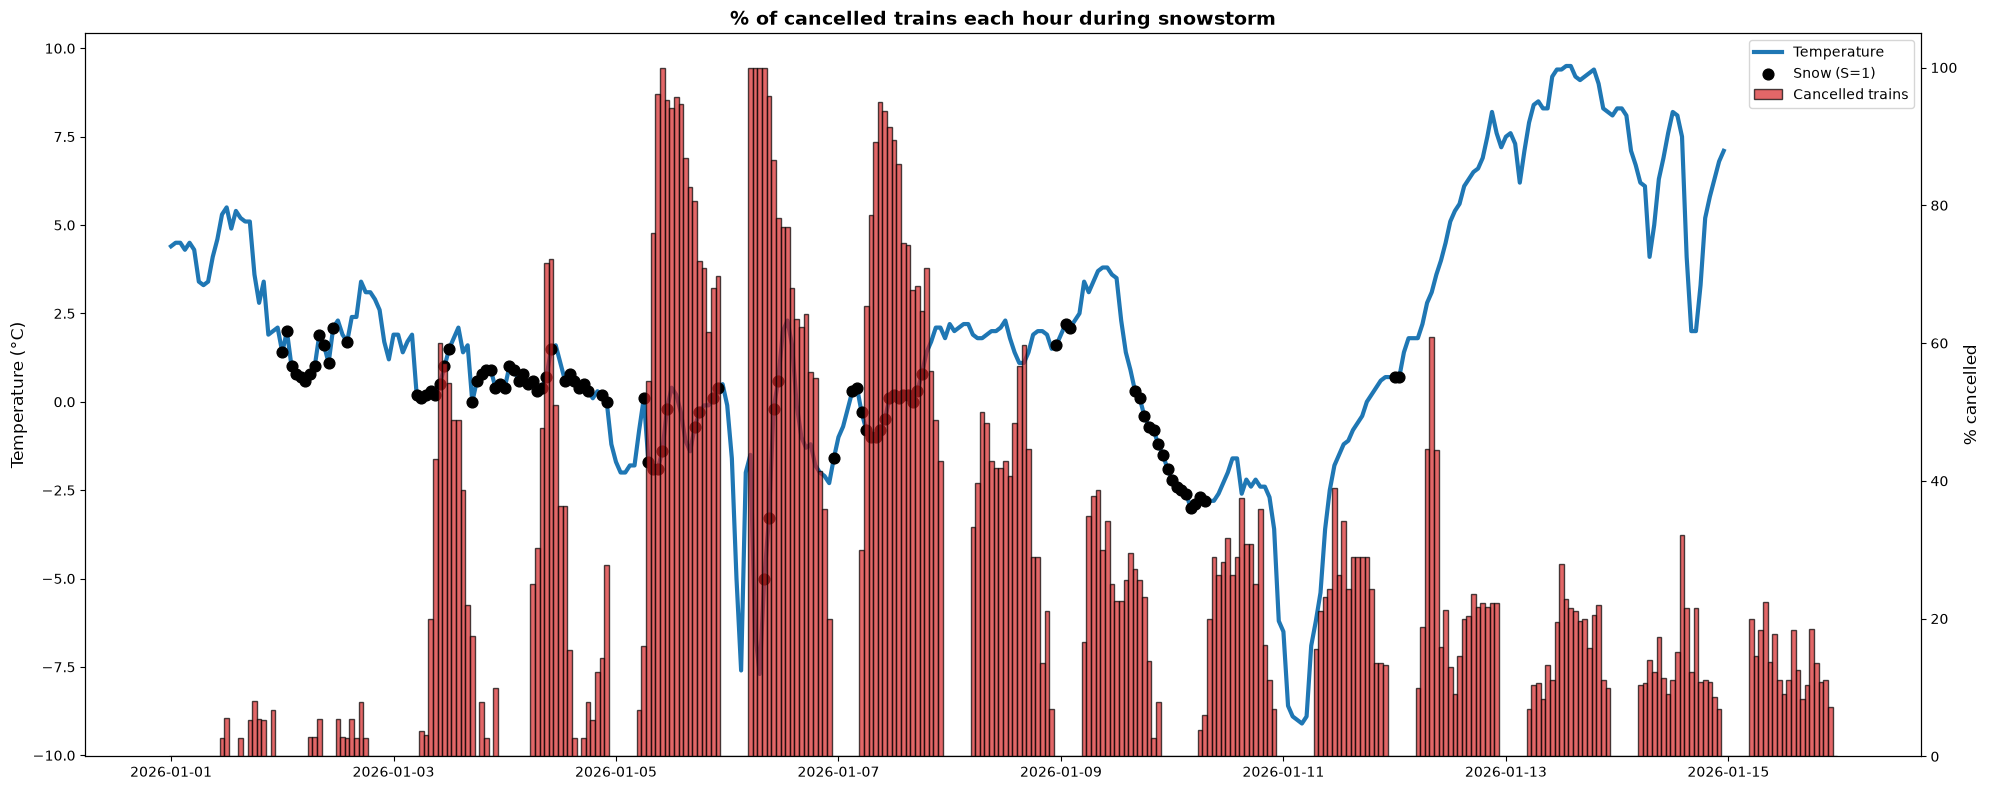

In [ ]:
#Visualisation cancelled trains
fig1, ax1 = plt.subplots(figsize=(20, 8))

#Plotting weather data

line1 = ax1.plot(df_weather['datetime'], df_weather['T_C'], label='Temperature', color='tab:blue', linewidth=3.0)
snow_df = df_weather[df_weather['S'] == 1]
scatter1 = ax1.scatter(snow_df['datetime'], snow_df['T_C'], color='black', s=60, zorder=5, label='Snow (S=1)')



#Setting up the train data
ax2 = ax1.twinx()
bar_width = pd.Timedelta(hours= 1)
bar1 = ax2.bar(time_period, total_to_percentage(hourly_cancelled, hourly_trains), label = 'Cancelled trains', color='tab:red', edgecolor='black', width=bar_width, alpha = 0.7)

#Setting up labels and titles
ax1.set_title(f'% of cancelled trains each hour during snowstorm', fontsize=14, fontweight='bold')
plt.xlabel('Datum en Tijdstip', fontsize=12)
ax1.set_ylabel('Temperature (°C)', fontsize=12)
ax2.set_ylabel('% cancelled', fontsize=12)


#Setting up legend
lines = line1 + [scatter1] + [bar1]
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper right')

plt.tight_layout()
plt.show()



In [ ]:
#Visualisation punctuality

fig1, ax1 = plt.subplots(figsize=(20, 8))

#Plotting weather data

line1 = ax1.plot(df_weather['datetime'], df_weather['T_C'], label='Temperature', color='tab:blue', linewidth=3.0)
snow_df = df_weather[df_weather['S'] == 1]
scatter1 = ax1.scatter(snow_df['datetime'], snow_df['T_C'], color='black', s=60, zorder=5, label='Snow (S=1)')



#Setting up the train data
ax2 = ax1.twinx()
bar_width = pd.Timedelta(hours= 1)
bar1 = ax2.bar(time_period, hourly_punctuality, label = 'Cancelled trains', color='tab:red', edgecolor='black', width=bar_width, alpha = 0.7)

#Setting up labels and titles
ax1.set_title(f'% of cancelled trains each hour during snowstorm', fontsize=14, fontweight='bold')
plt.xlabel('Datum en Tijdstip', fontsize=12)
ax1.set_ylabel('Temperature (°C)', fontsize=12)
ax2.set_ylabel('% cancelled', fontsize=12)


#Setting up legend
lines = line1 + [scatter1] + [bar1]
labels = [l.get_label() for l in lines]
print(labels)
ax1.legend(lines, labels, loc='upper right')

plt.tight_layout()
plt.show()